# Auto-Sklearn

In [ ]:
# 1. Instalar dependências de sistema do Linux necessárias para compilar pacotes do auto-sklearn
!sudo apt-get update
!sudo apt-get install -y build-essential swig python3-dev python3.8-dev python3.8-venv

# 2. Criar um ambiente virtual limpo usando o Python 3.8 que foi instalado
!python3.8 -m venv autosklearn_env

# 3. Atualizar pip, setuptools e wheel dentro do ambiente virtual, e instalar o auto-sklearn
!source autosklearn_env/bin/activate && pip install --upgrade pip setuptools wheel
!source autosklearn_env/bin/activate && pip install auto-sklearn matplotlib matplotlib_inline seaborn ipython

!pip install flaml

Get:1 https://cli.github.com/packages stable InRelease [3,917 B]
Hit:2 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease
Hit:3 http://security.ubuntu.com/ubuntu noble-security InRelease
Hit:4 http://archive.ubuntu.com/ubuntu noble InRelease
Hit:5 https://r2u.stat.illinois.edu/ubuntu noble InRelease
Hit:6 http://archive.ubuntu.com/ubuntu noble-updates InRelease
Hit:7 http://archive.ubuntu.com/ubuntu noble-backports InRelease
Hit:8 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease
Fetched 3,917 B in 1s (3,676 B/s)
Reading package lists... Done
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
build-essential is already the newest version (12.10ubuntu1).
swig is already the newest version (4.2.0-2ubuntu1).
python3-dev

In [ ]:
!source autosklearn_env/bin/activate && pip list

Package             Version
------------------- --------
asttokens           3.0.2
auto-sklearn        0.15.0
backcall            0.2.0
click               8.1.8
cloudpickle         3.1.2
ConfigSpace         0.4.21
contourpy           1.1.1
cycler              0.12.1
Cython              3.2.9
dask                2023.5.0
decorator           5.3.1
distributed         2023.5.0
distro              1.9.0
emcee               3.1.6
executing           2.3.0
FLAML               2.1.2
fonttools           4.57.0
fsspec              2025.3.0
importlib_metadata  8.5.0
importlib_resources 6.4.5
ipython             8.12.3
jedi                0.19.2
Jinja2              3.1.6
joblib              1.4.2
kiwisolver          1.4.7
liac-arff           2.5.0
lightgbm            4.6.0
locket              1.0.0
MarkupSafe          2.1.5
matplotlib          3.7.5
matplotlib-inline   0.1.7
msgpack             1.1.1
numpy               1.24.4
nvidia-nccl-cu12    2.32.3
packaging           26.2
pandas           

In [ ]:
%%writefile auto-sklearn.py
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn.datasets
import sklearn.metrics
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from autosklearn.classification import AutoSklearnClassifier

RANDOM_STATE = 42

# 1. Carregar dados
x, y = sklearn.datasets.load_iris(return_X_y=True)
x_train, x_test, y_train, y_test = train_test_split(x, y, random_state=RANDOM_STATE, stratify=y)

# 2. Configurar e treinar o classificador do auto-sklearn
autosklearn = AutoSklearnClassifier(
    time_left_for_this_task=120,
    per_run_time_limit=30,
    resampling_strategy='holdout'
)

print("Iniciando o treinamento do Auto-Sklearn no ambiente virtual...")
autosklearn.fit(x_train, y_train)

# 3. Gerar previsões e calcular métricas
y_pred = autosklearn.predict(x_test)
accuracy = sklearn.metrics.accuracy_score(y_test, y_pred)

# 4. Obter estatísticas das rodadas do AutoML
print(autosklearn.sprint_statistics())
print("Treinamento concluído e resultados exportados com sucesso!")

print("=== ESTATÍSTICAS DO AUTO-SKLEARN ===")
print(f"Acurácia Final: {float(accuracy):.4%}\n")

# Criar Matriz de Confusão com os resultados carregados
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=['Setosa', 'Versicolor', 'Virginica'], yticklabels=['Setosa', 'Versicolor', 'Virginica'])
plt.title("Matriz de Confusão (Dados do Auto-Sklearn)")
plt.xlabel("Previsão")
plt.ylabel("Real")

# Salvar a imagem para ser exibida no notebook posteriormente
plt.savefig('confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.close()
print("Gráfico salvo com sucesso como 'confusion_matrix.png'")

Overwriting auto-sklearn.py


In [ ]:
!./autosklearn_env/bin/python auto-sklearn.py

Iniciando o treinamento do Auto-Sklearn no ambiente virtual...
[WARNING] [2026-11-10 15:21:28,858:smac.runhistory.runhistory2epm.RunHistory2EPM4LogCost] Got cost of smaller/equal to 0. Replace by 0.000010 since we use log cost.
[WARNING] [2026-11-10 15:21:30,203:smac.runhistory.runhistory2epm.RunHistory2EPM4LogCost] Got cost of smaller/equal to 0. Replace by 0.000010 since we use log cost.
[WARNING] [2026-11-10 15:21:36,421:smac.runhistory.runhistory2epm.RunHistory2EPM4LogCost] Got cost of smaller/equal to 0. Replace by 0.000010 since we use log cost.
[WARNING] [2026-11-10 15:21:37,967:smac.runhistory.runhistory2epm.RunHistory2EPM4LogCost] Got cost of smaller/equal to 0. Replace by 0.000010 since we use log cost.
[WARNING] [2026-11-10 15:21:40,036:smac.runhistory.runhistory2epm.RunHistory2EPM4LogCost] Got cost of smaller/equal to 0. Replace by 0.000010 since we use log cost.
[WARNING] [2026-11-10 15:21:42,255:smac.runhistory.runhistory2epm.RunHistory2EPM4LogCost] Got cost of smaller/eq

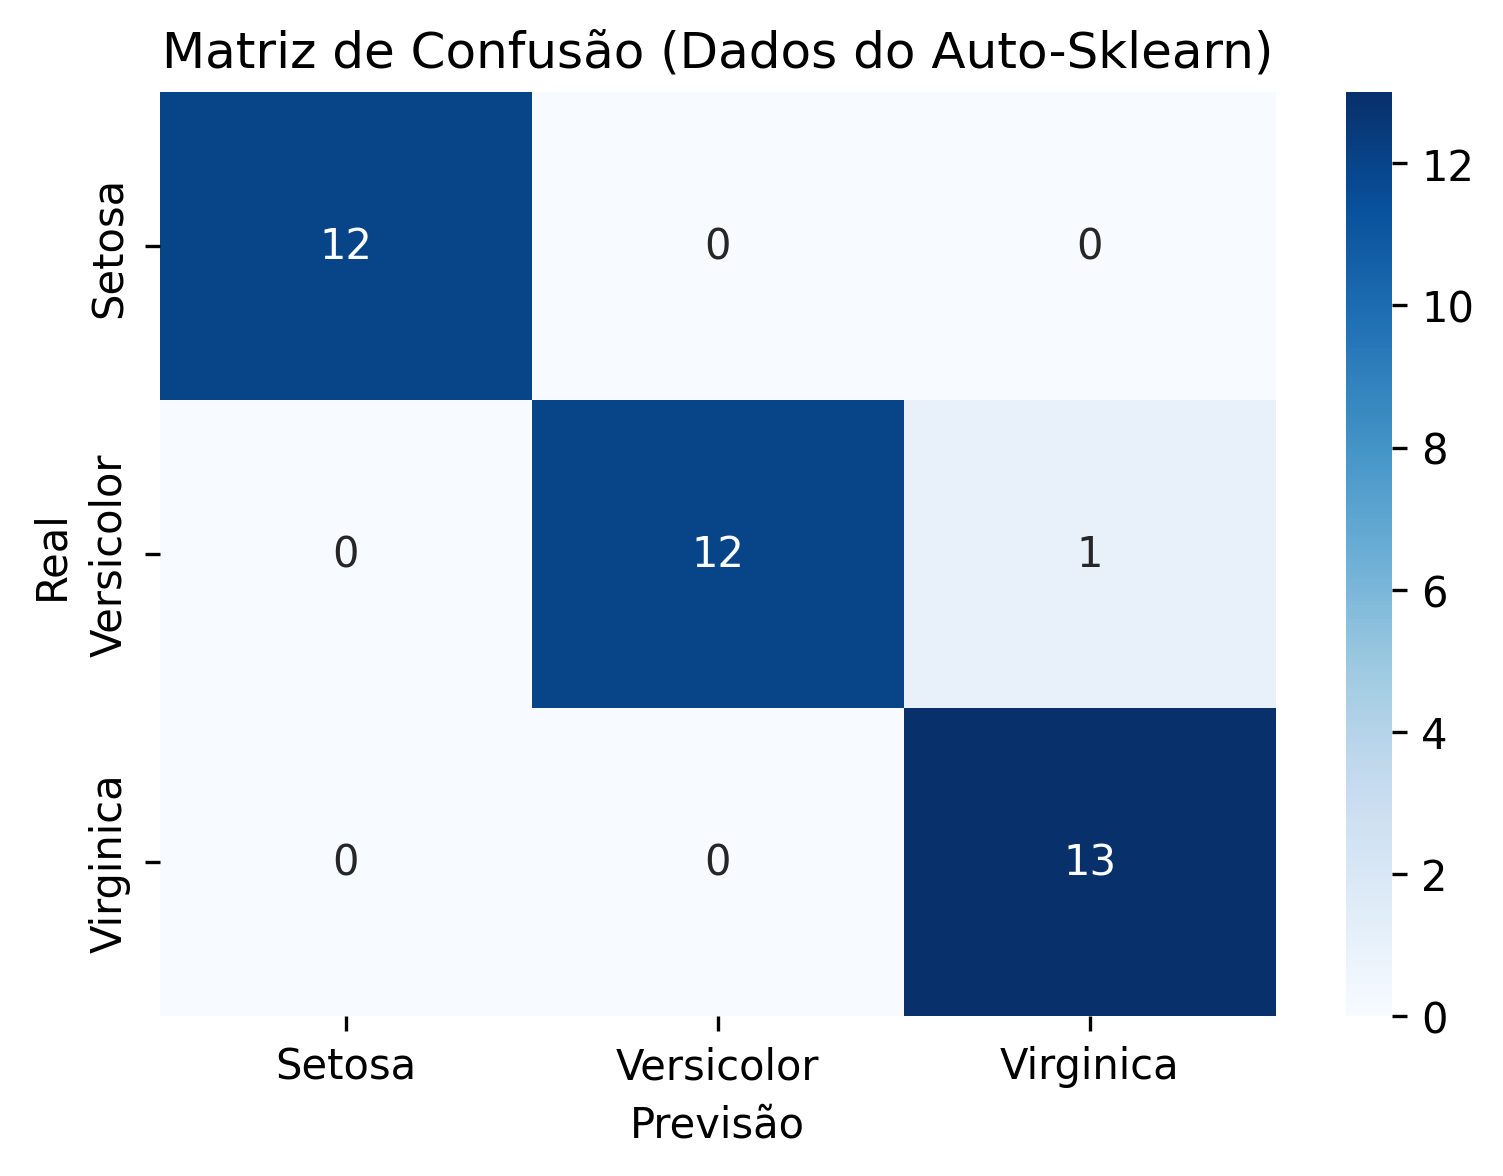

In [ ]:
from IPython.display import Image, display

# Exibir a imagem gerada pelo script Python executado no ambiente virtual
try:
    display(Image(filename='confusion_matrix.png'))
except FileNotFoundError:
    print("A imagem do gráfico não foi encontrada. Certifique-se de executar o script acima primeiro.")

# FLAML

Iniciando o treinamento do FLAML AutoML no ambiente virtual...
[flaml.automl.logger: 11-10 16:04:13] {2484} INFO - task = classification
[flaml.automl.logger: 11-10 16:04:13] {2495} INFO - Evaluation method: cv
[flaml.automl.logger: 11-10 16:04:13] {2604} INFO - Minimizing error metric: 1-accuracy
[flaml.automl.logger: 11-10 16:04:13] {2721} INFO - List of ML learners in AutoML Run: ['lgbm', 'rf', 'xgboost', 'extra_tree', 'xgb_limitdepth', 'sgd', 'lrl1']
[flaml.automl.logger: 11-10 16:04:13] {3026} INFO - iteration 0, current learner lgbm


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[flaml.automl.logger: 11-10 16:04:14] {3161} INFO - Estimated sufficient time budget=2773s. Estimated necessary time budget=64s.
[flaml.automl.logger: 11-10 16:04:14] {3212} INFO -  at 0.3s,	estimator lgbm's best error=5.3360e-02,	best estimator lgbm's best error=5.3360e-02
[flaml.automl.logger: 11-10 16:04:14] {3026} INFO - iteration 1, current learner lgbm


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[flaml.automl.logger: 11-10 16:04:14] {3212} INFO -  at 0.9s,	estimator lgbm's best error=5.3360e-02,	best estimator lgbm's best error=5.3360e-02
[flaml.automl.logger: 11-10 16:04:14] {3026} INFO - iteration 2, current learner sgd


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
INFO:flaml.tune.searcher.blendsearch:No low-cost partial config given to the search algorithm. For cost-frugal search, consider providing low-cost values for cost-related hps via 'low_cost_partial_config'. More info can be found at https://microsoft.github.io/FLAML/docs/FAQ#about-low_cost_partial_config-in-tune


... (297 outputs left out)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[flaml.automl.logger: 11-10 16:06:13] {3212} INFO -  at 119.6s,	estimator extra_tree's best error=1.7787e-02,	best estimator extra_tree's best error=1.7787e-02
[flaml.automl.logger: 11-10 16:06:13] {3026} INFO - iteration 593, current learner lrl1


INFO:flaml.tune.searcher.blendsearch:No low-cost partial config given to the search algorithm. For cost-frugal search, consider providing low-cost values for cost-related hps via 'low_cost_partial_config'. More info can be found at https://microsoft.github.io/FLAML/docs/FAQ#about-low_cost_partial_config-in-tune


[flaml.automl.logger: 11-10 16:06:13] {3212} INFO -  at 119.7s,	estimator lrl1's best error=3.5968e-02,	best estimator extra_tree's best error=1.7787e-02
[flaml.automl.logger: 11-10 16:06:13] {3026} INFO - iteration 594, current learner lrl1
[flaml.automl.logger: 11-10 16:06:13] {3212} INFO -  at 119.8s,	estimator lrl1's best error=3.5968e-02,	best estimator extra_tree's best error=1.7787e-02
[flaml.automl.logger: 11-10 16:06:13] {3026} INFO - iteration 595, current learner lrl1
[flaml.automl.logger: 11-10 16:06:13] {3212} INFO -  at 119.9s,	estimator lrl1's best error=3.5968e-02,	best estimator extra_tree's best error=1.7787e-02
[flaml.automl.logger: 11-10 16:06:13] {3026} INFO - iteration 596, current learner lrl1
[flaml.automl.logger: 11-10 16:06:13] {3212} INFO -  at 120.0s,	estimator lrl1's best error=3.5968e-02,	best estimator extra_tree's best error=1.7787e-02
[flaml.automl.logger: 11-10 16:06:13] {3474} INFO - retrain extra_tree for 0.0s
[flaml.automl.logger: 11-10 16:06:13] {3

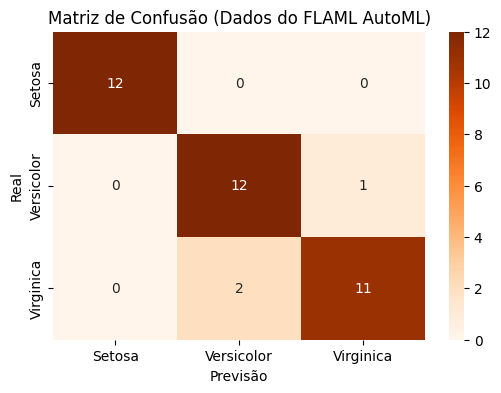

None

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn.datasets
import sklearn.metrics
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from flaml import AutoML

RANDOM_STATE = 42

# 1. Carregar dados
x, y = sklearn.datasets.load_iris(return_X_y=True)
x, y = pd.DataFrame(x), pd.Series(y)
x_train, x_test, y_train, y_test = train_test_split(x, y, random_state=RANDOM_STATE, stratify=y)

# 2. Configurar e treinar o classificador do FLAML AutoML
automl = AutoML(
    time_budget=120,
    metric="accuracy",
    task="classification",
    log_file_name="flaml.log",
    seed=RANDOM_STATE,
)

pipeline = Pipeline(steps=[
    ("prep", StandardScaler()),
    ("clf", automl),
])

print("Iniciando o treinamento do FLAML AutoML no ambiente virtual...")
pipeline.fit(x_train, y_train)

# 3. Gerar previsões e calcular métricas
y_pred = pipeline.predict(x_test)
accuracy = sklearn.metrics.accuracy_score(y_test, y_pred)

# 4. Obter estatísticas do melhor modelo encontrado pelo FLAML
print("=== ESTATÍSTICAS DO FLAML ===")
print(f"Melhor modelo encontrado: {automl.best_estimator}")
print(f"Melhores hiperparâmetros: {automl.best_config}")
print(f"Melhor acurácia de validação: {1 - automl.best_loss:.4%}")
print(f"Acurácia Final no Teste: {float(accuracy):.4%}\n")

# Criar Matriz de Confusão com os resultados do FLAML
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Oranges", xticklabels=['Setosa', 'Versicolor', 'Virginica'], yticklabels=['Setosa', 'Versicolor', 'Virginica'])
plt.title("Matriz de Confusão (Dados do FLAML AutoML)")
plt.xlabel("Previsão")
plt.ylabel("Real")
display(plt.show())

# Comparação de Resultados: Auto-Sklearn vs FLAML

| Biblioteca AutoML | Acurácia no Conjunto de Teste |
| :--- | :--- |
| **Auto-Sklearn** | 97.3684% |
| **FLAML AutoML** | 92.1053% |